In [1]:
#imports and calibration

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "config").exists() else cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from config.model_config import get_config
from src.severity import draw_severity, copula_transform
from src.calibration import (
    calibrate_probabilities,
    draw_incident_indicators,
    reputation_probabilities,
)

config = calibrate_probabilities(get_config())
rng = np.random.default_rng(42)

print("Calibration complete!")

Calibration complete!


In [ ]:
#Examine the calibrated intercepts
#The intercepts will differ across models because they must account for severity, visibility, and any required gating.

rows = []

for name, model in config["probabilities"].items():
    rows.append({
        "Model": name,
        "Target probability": model["target"],
        "Severity OR": model["severity_or"],
        "Visibility OR": model["visibility_or"],
        "Calibrated intercept": model["intercept"],
    })

calibration_table = pd.DataFrame(rows)
display(calibration_table)

,Model,Target probability,Severity OR,Visibility OR,Calibrated intercept
0,public_visibility,0.3000,2.0,1.0,-0.935500
1,notification,0.7500,2.0,1.0,1.209667
2,regulatory_engagement,0.1000,2.0,1.0,-2.381352
3,external_pr_agency,0.3000,1.5,3.0,-1.269803
4,regulatory_fine,0.0500,2.0,1.0,-0.413499
5,judgment_or_settlement,0.0500,2.0,3.0,-3.700802
6,affected_churn,0.0020,1.5,2.0,-6.694653
7,unaffected_churn,0.0002,1.3,2.0,-8.760497
8,lost_deal,0.0100,1.5,3.0,-5.207957


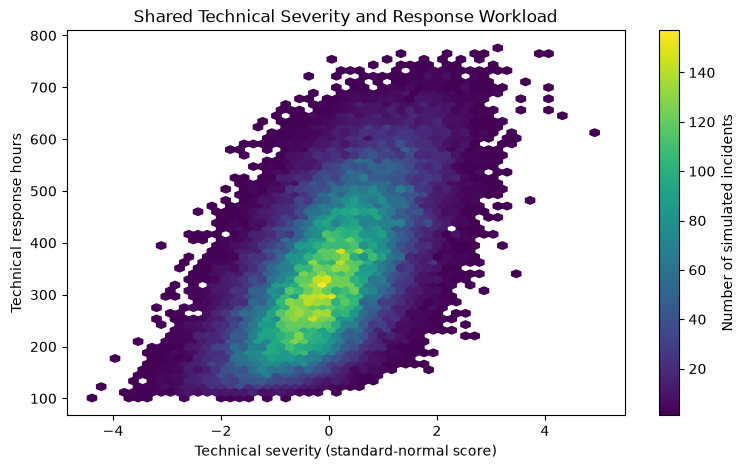

Observed Pearson correlation: 0.594


In [3]:
#Visualize severity versus technical response hours
n = 50_000

severity = draw_severity(rng, size=n)

spec = config["primary_response"]["technical_response_hours"]
rho = config["dependence"]["correlations_latent_normal"][
    "technical_response_hours"
]

technical_hours = copula_transform(
    severity, rho, spec, rng
)

plt.figure(figsize=(9, 5))
plt.hexbin(
    severity,
    technical_hours,
    gridsize=55,
    mincnt=1,
    cmap="viridis"
)
plt.colorbar(label="Number of simulated incidents")
plt.xlabel("Technical severity (standard-normal score)")
plt.ylabel("Technical response hours")
plt.title("Shared Technical Severity and Response Workload")
plt.show()

print(
    "Observed Pearson correlation:",
    round(np.corrcoef(severity, technical_hours)[0, 1], 3)
)

# Should see a positive relationship: higher technical severity generally corresponds to more response hours.
# The observed Pearson correlation will not necessarily equal 0.60, because 0.60 is the correlation between the underlying normal scores.

In [ ]:
#Validate the regulatory engagement → fine relationship

n = 500_000
severity = draw_severity(rng, size=n)

indicators = draw_incident_indicators(
    severity, config, rng
)

reg = indicators["regulatory_engagement"]
fine = indicators["regulatory_fine"]

print(f"Regulatory engagement rate: {reg.mean():.3%}")
print(f"Overall fine rate:          {fine.mean():.3%}")
print(f"Fine rate if engaged:       {fine[reg].mean():.3%}")
print(f"Fines without engagement:   {np.sum(fine & ~reg)}")

#Expected results, approximately:
#Metric	Expected
#Regulatory engagement	10%
#Overall fine occurrence	5%
#Fine occurrence among engaged incidents	50%
#Fines without engagement	0

Regulatory engagement rate: 9.999%
Overall fine rate:          4.995%
Fine rate if engaged:       49.956%
Fines without engagement:   0


In [ ]:
# Check unconditional occurrence probabilities

targets = config["probabilities"]

names = [
    "public_visibility",
    "notification",
    "regulatory_engagement",
    "external_pr_agency",
    "regulatory_fine",
    "judgment_or_settlement",
]

comparison = pd.DataFrame({
    "Event": names,
    "Target": [targets[name]["target"] for name in names],
    "Simulated": [indicators[name].mean() for name in names],
})

comparison["Difference"] = (
    comparison["Simulated"] - comparison["Target"]
)

display(comparison)

# All differences should be small.

,Event,Target,Simulated,Difference
0,public_visibility,0.30,0.299764,-0.000236
1,notification,0.75,0.750078,0.000078
2,regulatory_engagement,0.10,0.099992,-0.000008
3,external_pr_agency,0.30,0.300294,0.000294
4,regulatory_fine,0.05,0.049952,-0.000048
5,judgment_or_settlement,0.05,0.050214,0.000214
